# Lecture 3 — Grover & Amplitude Amplification (UnitaryLab companion)

This notebook demonstrates Grover's search on $n=3$ qubits (8 items, one marked)
using the UnitaryLab simulator (v1.1.4). Run the cells top to bottom.

Contents:
1. The oracle (phase flip on the marked item) and the diffusion operator
2. Success probability vs. iteration count, and the peak near $k=2$
3. A short discussion of the optimal number of iterations

In [1]:
import numpy as np
from unitarylab.core import Circuit

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline

n = 3
N = 2**n            # 8 items
marked = 5          # the marked basis state |101>

## 1. Deutsch–Jozsa and Bernstein–Vazirani (one quantum query)

Before Grover, the chapter's first algorithms show a clean quantum advantage with a *single* query. Both use the same circuit — $H^{\otimes n}$, a **phase oracle** $|x\rangle\mapsto(-1)^{f(x)}|x\rangle$, then $H^{\otimes n}$ — and read the answer straight off the measurement.

- **Deutsch–Jozsa:** $f$ is promised constant or balanced; the all-zeros outcome occurs with probability $1$ iff $f$ is *constant*.
- **Bernstein–Vazirani:** $f_s(x)=s\cdot x$; the phase oracle is a $Z$ on each qubit where $s_i=1$, and the measurement returns the hidden string $s$ in **one** query (classically $n$ are needed).

In [ ]:
# Phase oracle (-1)^{f(x)} applied in place; H^n before and after, then read the outcome.
def run_hoh(oracle, n):
    qc = Circuit(n)
    for q in range(n): qc.h(q)
    oracle(qc)
    for q in range(n): qc.h(q)
    return np.abs(qc.execute(backend='numpy', dtype=np.complex128).state) ** 2

n = 3
# --- Deutsch-Jozsa: constant vs balanced ---
P_const = run_hoh(lambda qc: None, n)        # f(x)=0 (constant): phase oracle = identity
P_bal   = run_hoh(lambda qc: qc.z(0), n)     # f(x)=x_0 (balanced): phase oracle = Z on qubit 0
print(f'Deutsch-Jozsa  constant: P(000) = {P_const[0]:.3f}  -> constant')
print(f'Deutsch-Jozsa  balanced: P(000) = {P_bal[0]:.3f}  -> balanced')
assert P_const[0] > 0.999 and P_bal[0] < 1e-9

# --- Bernstein-Vazirani: recover the hidden string s in one query ---
def bv_recover(s, n):
    def oracle(qc):
        for q in range(n):
            if (s >> q) & 1: qc.z(q)         # (-1)^{s.x} = product of Z over the s-qubits
    return int(np.argmax(run_hoh(oracle, n)))

print('\nBernstein-Vazirani (1 query each):')
for s in [0b101, 0b110, 0b011]:
    got = bv_recover(s, n)
    print(f'  hidden s = {s:0{n}b}  ->  recovered {got:0{n}b}')
    assert got == s
print('\nAll one-query algorithms verified.')

## 2. Oracle and diffusion

**Oracle** $O_f$ flips the sign of the amplitude of the marked state:
$O_f|x\rangle = (-1)^{[x=\text{marked}]}|x\rangle$. We implement it as a
multi-controlled-$Z$: surround an `mcx` (with the last qubit as target) by
Hadamards on that target so the controlled-$X$ becomes a controlled-$Z$, and use
$X$ gates to select the marked control pattern.

**Diffusion** $D = 2|s\rangle\langle s| - I$ reflects about the uniform
superposition $|s\rangle = H^{\otimes n}|0\rangle$. It is
$H^{\otimes n}(2|0\rangle\langle0| - I)H^{\otimes n}$, and the middle reflection
is again a multi-controlled-$Z$ about $|0\dots0\rangle$.

In [2]:
def apply_mcz(qc, qubits):
    '''Multi-controlled Z on the given qubits (phase flip of the all-ones state).'''
    *controls, target = qubits
    qc.h(target)
    qc.mcx(controls, target)
    qc.h(target)

def apply_oracle(qc, marked, n):
    '''Phase-flip the |marked> basis state.'''
    bits = [(marked >> q) & 1 for q in range(n)]   # bit for qubit q (q=0 is LSB)
    for q in range(n):
        if bits[q] == 0:
            qc.x(q)
    apply_mcz(qc, list(range(n)))
    for q in range(n):
        if bits[q] == 0:
            qc.x(q)

def apply_diffusion(qc, n):
    for q in range(n): qc.h(q)
    for q in range(n): qc.x(q)
    apply_mcz(qc, list(range(n)))
    for q in range(n): qc.x(q)
    for q in range(n): qc.h(q)

## 3. Success probability vs. iteration count

We build the full Grover circuit for $k$ iterations, read off the exact
statevector, and record the probability of the marked item.

In [3]:
def grover_success_prob(k, marked, n):
    qc = Circuit(n, name=f'grover_k{k}')
    for q in range(n): qc.h(q)                 # uniform superposition
    for _ in range(k):
        apply_oracle(qc, marked, n)
        apply_diffusion(qc, n)
    res = qc.execute(backend='numpy', dtype=np.complex128)
    probs = res.probabilities
    key = format(marked, f'0{n}b')             # keys read q_{n-1}...q_0 == big-endian of the integer
    return probs.get(key, 0.0)

ks = list(range(0, 6))
succ = [grover_success_prob(k, marked, n) for k in ks]
for k, p in zip(ks, succ):
    print(f'k={k}: P(marked) = {p:.4f}')

peak_k = int(np.argmax(succ))
print('peak at k =', peak_k, ' with P =', round(succ[peak_k], 4))
assert peak_k == 2, 'For N=8 the optimal iteration count is 2'
assert succ[2] > 0.9, 'Peak success probability should exceed 0.9'
print('asserts passed: peak at k=2 with probability > 0.9')

k=0: P(marked) = 0.1250
k=1: P(marked) = 0.7813
k=2: P(marked) = 0.9453
k=3: P(marked) = 0.3301
k=4: P(marked) = 0.0122
k=5: P(marked) = 0.5480
peak at k = 2  with P = 0.9453
asserts passed: peak at k=2 with probability > 0.9


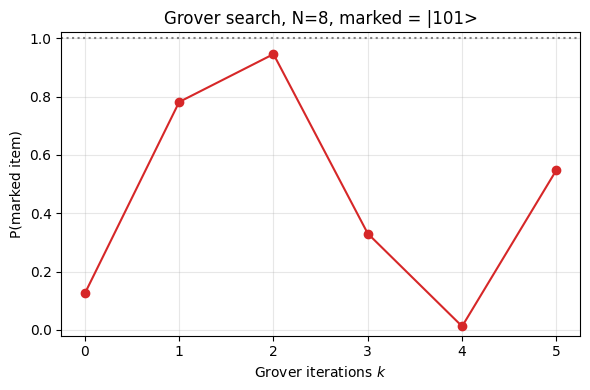

In [4]:
plt.figure(figsize=(6,4))
plt.plot(ks, succ, 'o-', color='C3')
plt.axhline(1.0, ls=':', color='gray')
plt.xlabel('Grover iterations $k$'); plt.ylabel('P(marked item)')
plt.title(f'Grover search, N={N}, marked = |{format(marked, f"0{n}b")}>')
plt.ylim(-0.02, 1.02); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

## 4. Optimal iterations

The theory says the optimal number of iterations is about
$\frac{\pi}{4}\sqrt{N/M}$ for $M$ marked items. With $N=8$, $M=1$ this is
$\frac{\pi}{4}\sqrt{8}\approx 2.22$, so $k=2$ is optimal — matching the peak above.
Over-rotating (e.g. $k=4$) *reduces* the success probability, illustrating that
Grover is a rotation in a 2D subspace, not a monotone amplifier.

In [5]:
k_opt = np.pi/4 * np.sqrt(N)
print('theoretical optimal k ~', round(k_opt, 3), '-> round to', round(k_opt))

theoretical optimal k ~ 2.221 -> round to 2


## 5. Building the oracle from a verifier (we never hardcode $x_0$)

The oracle in §1 phase-flips a *known* `marked` string — fine for illustration, but in a real search we do not know $x_0$. Instead we compile the oracle from a **verifier**: given an efficiently computable `g` and a known target `t`, we mark the (unknown) solution $x_0=g^{-1}(t)$ by **compute → mark $t$ → uncompute** on an ancilla register (`apply_mcz` from §1 supplies the multi-controlled $Z$). Grover then finds $x_0$ using only `g` and `t` — never $x_0$ itself.

In [ ]:
# Verifier: f(x) = 1 iff g(x) == t.  g mixes the bits (a Toffoli); t is the known target.
def g(x):
    x0, x1, x2 = x & 1, (x >> 1) & 1, (x >> 2) & 1
    return x0 | ((x0 ^ x1) << 1) | (((x0 & x1) ^ x2) << 2)

t = 5
x0_star = next(x for x in range(N) if g(x) == t)      # computed only to CHECK the result
print(f'target t = {t:0{n}b}; solution g^-1(t) = {x0_star} = {x0_star:0{n}b}',
      '(never used to build the oracle)')

def apply_Ug(qc, d, a):                               # |x>|0> -> |x>|g(x)>
    qc.cx(d[0], a[0])                                 # a0 = x0
    qc.cx(d[0], a[1]); qc.cx(d[1], a[1])              # a1 = x0 ^ x1
    qc.cx(d[2], a[2]); qc.mcx([d[0], d[1]], a[2])     # a2 = x2 ^ (x0 & x1)

def apply_Ug_dag(qc, d, a):                           # inverse: reverse the gate order
    qc.mcx([d[0], d[1]], a[2]); qc.cx(d[2], a[2])
    qc.cx(d[1], a[1]); qc.cx(d[0], a[1])
    qc.cx(d[0], a[0])

def oracle_from_verifier(qc, t, d, a):
    apply_Ug(qc, d, a)                                # 1. compute g(x) into the ancilla
    tb = [(t >> j) & 1 for j in range(len(a))]
    for j in range(len(a)):
        if tb[j] == 0: qc.x(a[j])                     # 2. mark: X-conjugated multi-ctrl Z, == t
    apply_mcz(qc, a)
    for j in range(len(a)):
        if tb[j] == 0: qc.x(a[j])
    apply_Ug_dag(qc, d, a)                            # 3. uncompute -> ancilla back to |0>

def apply_diffusion_on(qc, qubits):
    for q in qubits: qc.h(q)
    for q in qubits: qc.x(q)
    apply_mcz(qc, qubits)
    for q in qubits: qc.x(q)
    for q in qubits: qc.h(q)

def grover_verifier(k):
    data, anc = [0, 1, 2], [3, 4, 5]                  # 3 data qubits + 3 clean ancillas
    qc = Circuit(6, name=f'grover_verifier_k{k}')
    for q in data: qc.h(q)
    for _ in range(k):
        oracle_from_verifier(qc, t, data, anc)
        apply_diffusion_on(qc, data)
    p = np.abs(qc.execute(backend='numpy', dtype=np.complex128).state) ** 2
    P_x0     = sum(p[i] for i in range(2**6) if (i & 7) == x0_star)   # data == x0*, ancilla == 0
    anc_leak = sum(p[i] for i in range(2**6) if (i >> 3) != 0)        # should be ~0
    return P_x0, anc_leak

for k in range(5):
    P, leak = grover_verifier(k)
    print(f'k={k}: P(find x0*) = {P:.4f}   ancilla leakage = {leak:.1e}')

P2, leak2 = grover_verifier(2)
assert P2 > 0.9,     'k=2 should find the solution with probability > 0.9'
assert leak2 < 1e-9, 'ancillas must be uncomputed (no leakage back into the data)'
assert g(x0_star) == t, 'sanity: the recovered string really is a solution'
print(f'\nGrover recovered x0 = {x0_star:0{n}b} with probability {P2:.3f}, using only g and t.')

### Your turn
- Change `marked` to a different item (0–7) and confirm the peak stays at $k=2$.
- Mark **two** items and rebuild the oracle to flip both; the optimal $k$ drops to
  about $\frac{\pi}{4}\sqrt{8/2}=\pi/2\approx 1.57 \Rightarrow k=1$.
- Increase to $n=4$ ($N=16$) and check the peak moves to $k\approx 3$.